# 支付方式偏好分析

巴西电商的支付习惯：方式占比、分期行为与客单价差异。

               订单数           金额  平均分期    单均金额  订单占比%  金额占比%
type                                                       
boleto       19191   2769932.58  1.00  144.33  19.89  17.96
credit_card  73220  12122059.54  3.52  165.56  75.89  78.60
debit_card    1484    208371.12  1.00  140.41   1.54   1.35
voucher       2582    322098.53  1.47  124.75   2.68   2.09


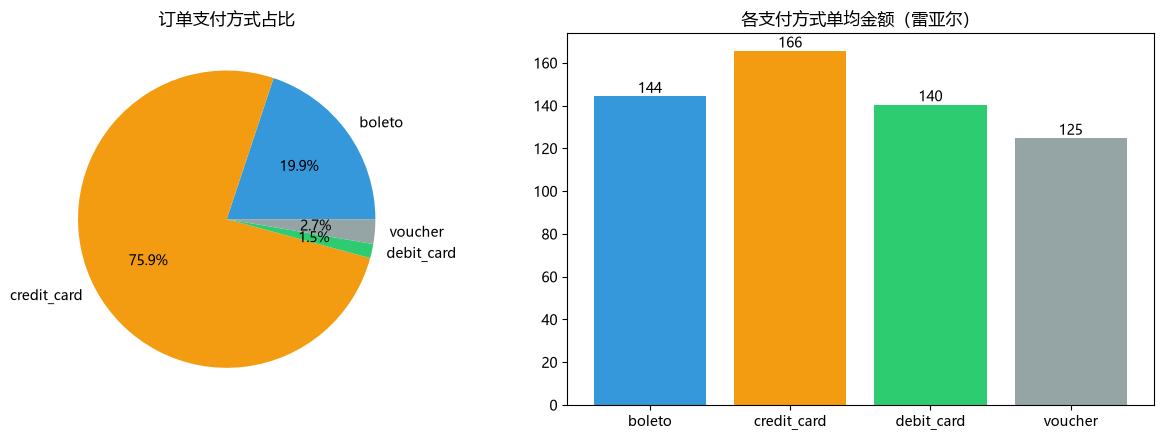

使用分期的订单占比 51.5%


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

payments = pd.read_csv('data/order_payments_clean.csv')
orders = pd.read_csv('data/orders_clean.csv', parse_dates=['order_purchase_timestamp'])
o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')

# 一单可能多笔支付，按订单聚合
ptype = payments.groupby('order_id').agg(
    type=('payment_type', 'first'), val=('payment_value', 'sum'),
    inst=('payment_installments', 'max'))
p = o[['order_id']].merge(ptype, on='order_id')

t = p.groupby('type').agg(订单数=('order_id', 'nunique'), 金额=('val', 'sum'),
                          平均分期=('inst', 'mean'), 单均金额=('val', 'mean'))
t['订单占比%'] = t['订单数'] / t['订单数'].sum() * 100
t['金额占比%'] = t['金额'] / t['金额'].sum() * 100
print(t.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].pie(t['订单数'], labels=t.index, autopct='%.1f%%',
            colors=['#3498db', '#f39c12', '#2ecc71', '#95a5a6'])
axes[0].set_title('订单支付方式占比')
axes[1].bar(t.index, t['单均金额'], color=['#3498db', '#f39c12', '#2ecc71', '#95a5a6'])
axes[1].set_title('各支付方式单均金额（雷亚尔）')
for i, v in enumerate(t['单均金额']):
    axes[1].text(i, v, f'{v:.0f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()
print('使用分期的订单占比 %.1f%%' % ((p['inst'] > 1).mean() * 100))


## 结论

- **信用卡绝对主导**：75.9% 订单、78.6% 金额；boleto（巴西线下缴费凭证）占 19.9%；借记卡与 voucher 合计约 4%。
- **分期是常态**：51.5% 的订单使用分期，信用卡平均分期 3.52 期，体现巴西消费信贷习惯。
- 信用卡单均金额（166）高于 boleto（144）——大额消费更依赖信用卡分期，信用卡分期额度是提客单价的抓手。

## 业务解读

- 信用卡 75.9% + 分期率 51.5% 是巴西「BNPL（先买后付）文化」的体现——分期不是促销手段而是基础设施，接入分期能力是进入巴西市场的门槛。
- boleto（线下缴费单）19.9% 服务无信用卡人群（年轻、低收入、银行信用不足），这部分用户客单价低 13%，但基数大，不应放弃。
- boleto 支付有 1–3 天确认延迟，会推迟发货时效——对 boleto 订单应做支付确认提速（如 PIX），否则拉长整体履约链路。
- voucher（企业/礼品卡）金额占比仅 2.1%，B2B 或企业福利是可挖掘的小众渠道。

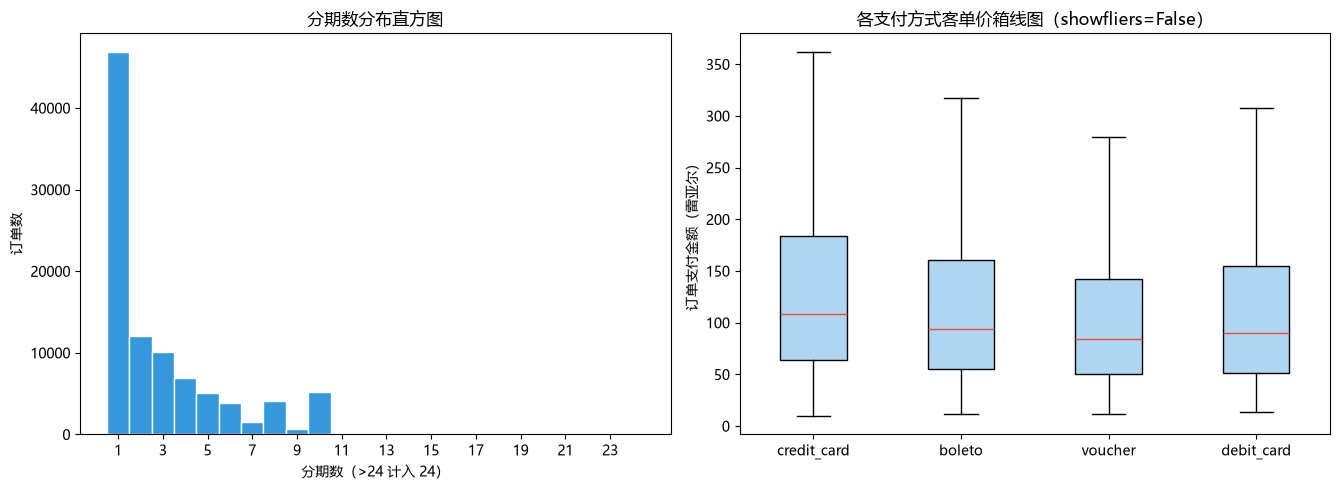

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# ① 分期数分布直方图（clip 到 24 期）
inst_c = p['inst'].clip(upper=24)
axes[0].hist(inst_c, bins=np.arange(0.5, 25.5, 1), color='#3498db', edgecolor='white')
axes[0].set_xticks(range(1, 25, 2))
axes[0].set_xlabel('分期数（>24 计入 24）'); axes[0].set_ylabel('订单数')
axes[0].set_title('分期数分布直方图')

# ② 各支付方式客单价箱线图（不含离群点）
type_order = p['type'].value_counts().index.tolist()
groups = [p.loc[p['type'] == t, 'val'].values for t in type_order]
axes[1].boxplot(groups, showfliers=False, patch_artist=True,
                boxprops={'facecolor': '#aed6f1'}, medianprops={'color': '#e74c3c'})
axes[1].set_xticks(range(1, len(type_order) + 1), type_order)
axes[1].set_ylabel('订单支付金额（雷亚尔）')
axes[1].set_title('各支付方式客单价箱线图（showfliers=False）')

plt.tight_layout()
plt.show()